# Land degradation and crop yield gaps: OLS and causal forests, step by step

This notebook re-runs the two model stages of the replication package for
**Hadi et al., *"Land degradation is associated with larger crop yield gaps across global croplands"* (Nature Food)**
using the Python port in `code_py/`. It uses the downloaded data in `Risk/hadi_model/data/`.

| Part | Question | Method | Output |
|---|---|---|---|
| **A** | By how many % does the yield gap rise, on average, when a degradation "debt" rises by 1 %? | log-log OLS with iid / HC1 / Conley SEs, a control ladder and robustness checks | elasticities (Figs. 2–3, Supp. Figs. 3, 5, 6) |
| **B** | *Where* is the effect larger or smaller? | one causal forest (GRF) per debt, continuous treatment | per-cell CATE maps (Supp. Figs. 8–14), used as inputs to the loss calculation |

Each step has three parts: **theory** (what is estimated and why), **rationale**
(why the paper made that choice), and **code**. The code reuses the helpers in
`code_py/_shared/` and the functions of `code_py/02_models/*.py`, so the notebook
and the scripts cannot drift apart.

> **Compute.** The OLS part runs on the full sample (about 570k cells) in minutes.
> The paper's causal forests (5 × 2000 trees on about 405k cells) take hours. The `RUN_MODE`
> switch below picks either a fast **demo** (subsample, few trees) or the exact **full** settings.

## 0. Setup and configuration

In [1]:
import importlib.util
import os
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
# pyfixest reports every collinear dummy it drops (see A2). Silence the repeats.
warnings.filterwarnings("ignore", message=r"(?s).*dropped due to multicollinearity")

# --- locate code_py/ (works when the notebook is run from code_py/ or from the repo root)
CODE_PY = next(p for p in [Path.cwd(), Path.cwd() / "Risk" / "hadi_model" / "code_py",
                           *Path.cwd().parents] if (p / "_shared" / "econometrics.py").exists())
sys.path.insert(0, str(CODE_PY))

from _shared import dataset_contract as dc
from _shared.econometrics import FitResult, avg_slopes, conley_vcov
from _shared.paths import DATA_ROOT, path_processed, path_raw


def load_script(name, relpath):
    # The script file names start with digits, so they are imported via importlib.
    # Only module-level definitions run; their main() is never called.
    spec = importlib.util.spec_from_file_location(name, CODE_PY / relpath)
    mod = importlib.util.module_from_spec(spec)
    sys.modules[name] = mod          # dataclasses look the module up here
    spec.loader.exec_module(mod)
    return mod


ols = load_script("ols_script", "02_models/01_fit_regression_models.py")
cfs = load_script("cf_script", "02_models/02_fit_causal_forests.py")

print("code_py  :", CODE_PY)
print("data root:", DATA_ROOT, "| exists:", DATA_ROOT.exists())

code_py  : c:\Users\loyola\OneDrive - World Wildlife Fund, Inc\Documents\203. Python projects\SBTN_Test\Risk\hadi_model\code_py
data root: C:\Users\loyola\OneDrive - World Wildlife Fund, Inc\Documents\203. Python projects\SBTN_Test\Risk\hadi_model\data | exists: True


### Run configuration

| Setting | `demo` | `full` (paper) |
|---|---|---|
| CF sample | `N_SUB` random cells (seed 42) | all ~405k complete cells |
| trees per causal forest | `NUM_TREES` = 200 | 2000 |
| nuisance forests (Ŷ, Ŵ) | max(50, trees/4) | 500 |
| CATE files | `*_demo.csv` | `*.csv/.parquet` + GeoTIFFs |

The OLS part always uses the full sample. `RUN_CONLEY` and `RUN_AVG_SLOPES` let you skip the
slower OLS extras.

In [2]:
RUN_MODE = "demo"          # "demo" | "full"

SEED = 42
NUM_THREADS = max(1, (os.cpu_count() or 2) - 2)
RUN_CONLEY = True          # Conley 100 km SEs for the baseline + ladder (a few minutes each)
RUN_AVG_SLOPES = True      # nonlinear OLS models + average marginal effects (analytic, cheap)
CF_SCALE = "raw"           # "raw" = as written in 02_fit_causal_forests.R; "log" = __rescaled__log Y and W
                           # (the published R CATEs look log-scale, see B5)

if RUN_MODE == "demo":
    N_SUB, NUM_TREES, SUFFIX = 50_000, 200, "_demo"
elif RUN_MODE == "full":
    N_SUB, NUM_TREES, SUFFIX = None, 2000, ""
else:
    raise ValueError(RUN_MODE)

OLS_OUT = {k: path_processed("models_py", k) for k in ("main_10km", "hc1", "conley_100km")}
CF_OUT = path_processed("causal_forest_py")
for d in [*OLS_OUT.values(), CF_OUT]:
    d.mkdir(parents=True, exist_ok=True)

# short labels for plots
LABEL = {"soilErosionDebt": "Erosion", "soilCompactionDebt": "Compaction",
         "soilOrganicCarbonDebt": "SOC", "soilWaterDebt": "Soil water", "treeCoverDebt": "Tree cover"}
LABEL.update({k + dc.LOG_SUFFIX: v for k, v in LABEL.items()})
COLORS = dict(zip(dc.TREATMENTS_RAW, ["#4C72B0", "#DD8452", "#55A868", "#8172B3", "#C44E52"]))
COLORS.update({k + dc.LOG_SUFFIX: v for k, v in list(COLORS.items())})
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

assert CF_SCALE in ("raw", "log")
if CF_SCALE == "log":
    SUFFIX += "_logscale"
print(f"RUN_MODE={RUN_MODE}  N_SUB={N_SUB}  NUM_TREES={NUM_TREES}  NUM_THREADS={NUM_THREADS}  CF_SCALE={CF_SCALE}")


class Timer:
    def __init__(self, label): self.label = label
    def __enter__(self): self.t = time.perf_counter(); return self
    def __exit__(self, *a): print(f"[{self.label}] {time.perf_counter() - self.t:,.1f} s")

RUN_MODE=demo  N_SUB=50000  NUM_TREES=200  NUM_THREADS=10  CF_SCALE=raw


## 1. The research question and the data

**Unit of analysis.** One row is one cropland grid cell of about 10 km (≈ 0.083°), identified by
`long`/`lat` at its centre. Only cells with an observed 2010 yield gap are kept.

**Outcome.** `AllCrops2010YieldGapPercent` is the aggregate yield gap in 2010 as % of attainable yield:

$$YG_i = 100\,\frac{Y^{att}_i - Y^{act}_i}{Y^{att}_i}.$$

**Treatments: five land-degradation "debts".** Each is a change relative to an earlier
reference state. Improvements are set to 0 (`pmax(x, 0)`), so a debt measures only deterioration:

| Treatment | Meaning |
|---|---|
| `soilErosionDebt` | increase in water erosion |
| `soilCompactionDebt` | subsoil compaction susceptibility |
| `soilOrganicCarbonDebt` | SOC lost between ~1983 and ~2010 |
| `soilWaterDebt` | soil-moisture decline, 1979–83 → 2008–12 |
| `treeCoverDebt` | tree-cover loss |

**Controls** come in three blocks:
* *natural*: climate levels and climate change, terrain, soil type and texture
* *adaptation*: fertilizer, manure, N deposition, P, pesticides, irrigation
* *socioeconomic*: HDI, GDP, institutions, infrastructure, machinery

This distinction matters for identification (Section A1).

In [3]:
with Timer("read .rds"):
    df_raw = dc.read_rds(dc.analysis_ready_dataset_path())
print(df_raw.shape)

groups = {
    "outcome": [dc.OUTCOME_RAW],
    "treatments": dc.TREATMENTS_RAW,
    "natural (climate/terrain/soil)": (dc.CONTROLS_environment_climateWc_RAW + dc.CONTROLS_environment_climateTerra_RAW
                                       + dc.CONTROLS_environment_timeDelta_climateTerra_RAW
                                       + dc.CONTROLS_environment_terrain_RAW + dc.CONTROLS_environment_soilGrid_RAW
                                       + [dc.CONTROLS_environment_soilType]),
    "adaptation": dc.CONTROLS_adaptation_RAW,
    "socioeconomic": dc.CONTROLS_socioeconomic_RAW,
    "crop-type dummies": dc.crop_type_dummy_vars,
    "robustness extras": dc.ROBUSTNESS_EXTRA_RAW + [dc.ROBUSTNESS_EXTRA_CATEGORICAL],
}
na = pd.DataFrame([
    {"group": g, "n_vars": len(v), "max % NA": 100 * df_raw[v].isna().mean().max(),
     "% rows complete": 100 * df_raw[v].notna().all(axis=1).mean()}
    for g, v in groups.items()
]).round(1)
na

[read .rds] 1.6 s
(572162, 126)


,group,n_vars,max % NA,% rows complete
0,outcome,1,0.0,100.0
1,treatments,5,22.9,71.6
2,natural (climate/terrain/soil),22,0.0,100.0
3,adaptation,8,2.0,97.1
4,socioeconomic,11,0.7,99.3
5,crop-type dummies,10,0.0,100.0
6,robustness extras,9,19.3,78.3


The adaptation and socioeconomic blocks have the most missing values. The causal forest needs complete rows,
so its sample (about 405k cells) is smaller than the OLS sample. Each OLS model drops incomplete rows
for its own variables (listwise deletion, as `fixest` does).

In [4]:
desc = df_raw[[dc.OUTCOME_RAW, *dc.TREATMENTS_RAW]].describe(percentiles=[.05, .5, .95]).T
desc["% zero"] = 100 * (df_raw[[dc.OUTCOME_RAW, *dc.TREATMENTS_RAW]] == 0).mean()
desc.round(3)

,count,mean,std,min,5%,50%,95%,max,% zero
AllCrops2010YieldGapPercent,572162.0,46.059,22.228,0.0,7.323,47.127,79.735,99.567,1.470
soilErosionDebt,572132.0,4.577,8.392,0.0,0.067,1.613,18.033,165.729,0.185
soilCompactionDebt,441249.0,0.403,0.483,0.0,0.000,0.171,1.442,2.000,22.579
soilOrganicCarbonDebt,570232.0,0.603,1.460,0.0,0.000,0.000,3.696,40.736,70.440
soilWaterDebt,509643.0,0.007,0.009,0.0,0.000,0.003,0.023,0.258,32.871
treeCoverDebt,572142.0,1246.451,871.423,0.0,165.148,1069.119,2919.420,7035.331,0.348


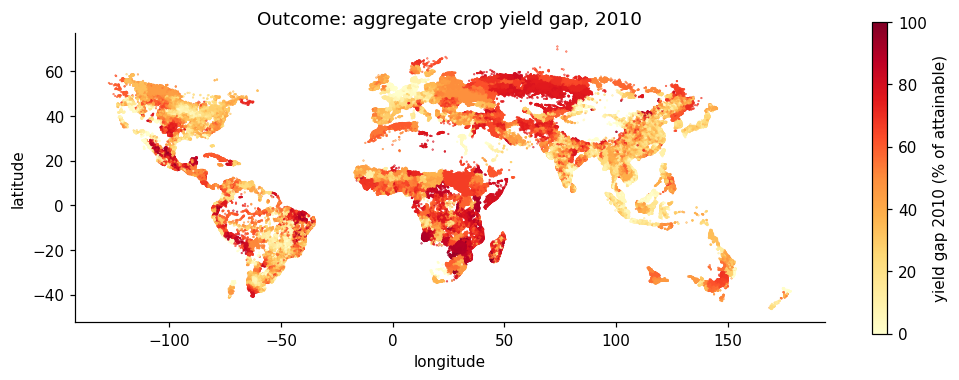

In [5]:
fig, ax = plt.subplots(figsize=(11, 4.6))
s = df_raw.sample(200_000, random_state=SEED) if len(df_raw) > 200_000 else df_raw
sc = ax.scatter(s["long"], s["lat"], c=s[dc.OUTCOME_RAW], s=0.15, cmap="YlOrRd", vmin=0, vmax=100, rasterized=True)
plt.colorbar(sc, ax=ax, label="yield gap 2010 (% of attainable)", shrink=0.8)
ax.set(title="Outcome: aggregate crop yield gap, 2010", xlabel="longitude", ylabel="latitude", aspect="equal")
plt.show()

## 2. The `__rescaled__log` transform

The data pipeline creates, for every numeric variable,

$$x^{r} = \frac{x - \min x}{\max x - \min x}\cdot 100 + 1 \;\in [1, 101], \qquad x^{rl} = \log x^{r} \;\in [0, \log 101].$$

**Rationale**
* Debts are often exactly 0 after clipping, so $\log x$ is undefined there. Shifting the range to start at 1 makes the log well defined, and a zero debt maps to 0.
* Logs compress the very skewed distributions of the debts and fertilizer, and they turn the coefficients into **elasticities**.
* The regressions (Part A) use only `__rescaled__log` variables. The forests (Part B) use the raw variables, because trees are invariant to monotone transforms of $X$.

**Caveat.** The elasticity is with respect to the *rescaled* variable. Since $x^r$ = affine$(x)$, a
1 % change in $x^r$ is not a 1 % change in $x$. Section C converts both models to a common unit
(yield-gap percentage points per raw debt unit).

The cell below recomputes the transform and checks it against the stored column.

In [6]:
def rescaled_log(x):
    return np.log((x - x.min()) / (x.max() - x.min()) * 100 + 1)

chk = pd.DataFrame({
    v: {"max |recomputed - stored|": np.nanmax(np.abs(rescaled_log(df_raw[v]) - df_raw[v + dc.LOG_SUFFIX]))}
    for v in [dc.OUTCOME_RAW, *dc.TREATMENTS_RAW]
}).T
chk

,max |recomputed - stored|
AllCrops2010YieldGapPercent,4.440892e-16
soilErosionDebt,4.440892e-16
soilCompactionDebt,8.881784e-16
soilOrganicCarbonDebt,4.440892e-16
soilWaterDebt,4.440892e-16
treeCoverDebt,8.881784e-16


The maximum difference is about 0 for every variable. The stored columns follow the documented formula.
(The yield-gap outcome uses the same formula. Only actual and attainable yield are rescaled with `x - min + 1`.)

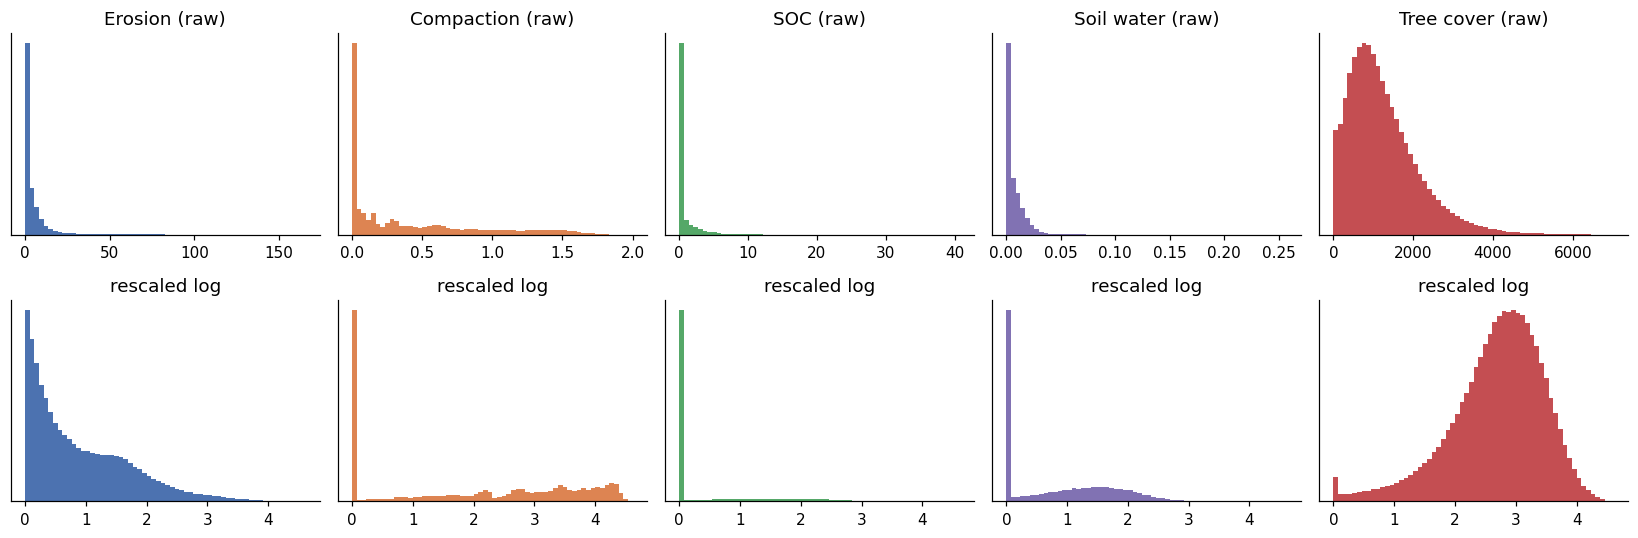

In [7]:
fig, axes = plt.subplots(2, 5, figsize=(15, 5))
for j, t in enumerate(dc.TREATMENTS_RAW):
    axes[0, j].hist(df_raw[t].dropna(), bins=60, color=COLORS[t]); axes[0, j].set_title(LABEL[t] + " (raw)")
    axes[1, j].hist(df_raw[t + dc.LOG_SUFFIX].dropna(), bins=60, color=COLORS[t]); axes[1, j].set_title("rescaled log")
for a in axes.ravel(): a.set_yticks([])
plt.tight_layout(); plt.show()

---
# Part A: log-log OLS

## A1. Theory

For cell $i$:

$$\log YG^{r}_i = \alpha + \sum_{k=1}^{5}\beta_k \log D^{r}_{ik} + \gamma' Z_i + \varepsilon_i .$$

* **Elasticity.** $\beta_k$ is the % change in the (rescaled) yield gap for a 1 % increase in (rescaled) debt $k$, *holding the other four debts and all controls $Z$ fixed*. All five debts enter together, so each $\beta_k$ is net of the co-occurring degradation processes.
* **Identification: selection on observables.** $\beta_k$ has a causal reading only if $E[\varepsilon \mid D, Z] = 0$, i.e. conditional on $Z$ the debts are as good as randomly assigned. The controls are chosen to absorb the main confounders: climate and climate change, terrain, inherent soil properties, management intensity, and institutions and wealth. Unobserved confounding cannot be ruled out, which is why the title says *"associated with"*.
* **Confounders vs. mediators ("bad controls").** Natural controls are pre-determined, so they are clear confounders. Adaptation and socioeconomic variables can partly be *responses* to degradation, e.g. farmers adding fertilizer or irrigation on degraded land. Conditioning on a mediator absorbs part of the effect. That motivates the **control ladder** (A4): if $\hat\beta$ is stable when these blocks are added, the choice of controls is not driving the result.

Estimation is plain OLS (`fixest::feols` in R, `pyfixest.feols` here, with no fixed effects).

## A2. Baseline specification

The baseline formula `f` comes from the script. It holds the 5 debts plus the natural, adaptation and socioeconomic
controls, all on the log scale, plus soil type as a categorical factor (one dummy per level, reference = first level).

In [8]:
# factor handling as in the script's main(): crop dummies, soil type and field-size class become categoricals
df_ok = df_raw.copy()
for c in [c for c in df_ok.columns if c.startswith("dominantCropGerberRay_")] + \
         [dc.CONTROLS_environment_soilType, dc.ROBUSTNESS_EXTRA_CATEGORICAL]:
    df_ok[c] = df_ok[c].astype("category")

f = ols.f
TREAT = dc.TREATMENTS_LOG
print("outcome :", f.outcome)
print("n terms :", len(f.terms), "| natural:", len(ols.natural_controls),
      "| adaptation:", len(dc.CONTROLS_adaptation_LOG), "| socioeconomic:", len(dc.CONTROLS_socioeconomic_LOG))
print("\nformula (truncated):\n", f.formula()[:400], "...")

outcome : AllCrops2010YieldGapPercent__rescaled__log
n terms : 46 | natural: 22 | adaptation: 8 | socioeconomic: 11

formula (truncated):
 AllCrops2010YieldGapPercent__rescaled__log ~ soilErosionDebt__rescaled__log + soilCompactionDebt__rescaled__log + soilOrganicCarbonDebt__rescaled__log + soilWaterDebt__rescaled__log + treeCoverDebt__rescaled__log + wc_srad__mean__rescaled__log + wc_tavg__mean__rescaled__log + wc_prec__mean__rescaled__log + wc_meanTempWarmestQuarter__mean__rescaled__log + wc_maxTempWarmestMonth__mean__rescaled__log ...


In [9]:
def tidy_treat(res, model=None):
    t = res.tidy()
    t = t[t["term"].isin(TREAT)].copy()
    t.insert(0, "debt", t["term"].map(LABEL))
    if model: t.insert(0, "model", model)
    return t.drop(columns="term")

with Timer("baseline OLS (iid)"):
    base_iid, base_data = ols.fit_model("model_baseline", f, df_ok, "iid")
print(f"n = {base_iid.nobs:,}   R² = {base_iid.r2:.3f}   k = {len(base_iid.coef)}")
tidy_treat(base_iid).round(4)

[baseline OLS (iid)] 2.7 s
n = 405,084   R² = 0.331   k = 56


,debt,estimate,std_error,statistic,p_value,conf_low,conf_high,vcov_type,nobs
1,Erosion,0.0443,0.0021,20.6633,0.0,0.0401,0.0486,iid,405084
2,Compaction,0.0570,0.0012,49.1732,0.0,0.0548,0.0593,iid,405084
3,SOC,0.0073,0.0014,5.1250,0.0,0.0045,0.0101,iid,405084
4,Soil water,0.0330,0.0013,25.6503,0.0,0.0305,0.0355,iid,405084
5,Tree cover,0.0335,0.0018,18.6396,0.0,0.0300,0.0370,iid,405084


*Note on dropped dummies.* pyfixest drops one soil-type level (`soil_type__mode[T.12]`), which is perfectly
collinear with the other regressors in the estimation sample. With crop-type controls it also drops one crop dummy:
the 10 dummies plus the intercept are collinear when every cell has a dominant crop. `fixest` drops the same columns
(shown as `NA` coefficients in R), so the debt coefficients are unaffected.

**Reading the table.** A positive $\hat\beta_k$ means that cells with more of debt $k$ have larger yield gaps,
conditional on everything else. With roughly half a million observations, iid standard errors are tiny. The
next step shows why they are too optimistic.

## A3. Standard errors: iid, HC1, Conley

**Why it matters.** Neighbouring 10 km cells share unobserved weather, soils, practices and
policy, so their residuals are correlated. iid and heteroskedasticity-robust (HC1) SEs treat every cell
as independent information, which overstates the effective sample size. This section builds the three
estimators from one common formula, so the differences between them are clear.

### A3.1 The sandwich: one formula for every variance estimator

Write the model in matrix form, $y = X\beta + u$, with $X$ the $n\times k$ design (intercept, 5 debts, controls, dummies).
The OLS estimator and its sampling error are

$$\hat\beta = (X'X)^{-1}X'y \quad\Rightarrow\quad \hat\beta - \beta = (X'X)^{-1}X'u .$$

Conditional on $X$, the variance is therefore

$$\operatorname{Var}(\hat\beta\mid X) = \underbrace{(X'X)^{-1}}_{\text{bread}}\;\underbrace{X'\,\Omega\,X}_{\text{meat}}\;\underbrace{(X'X)^{-1}}_{\text{bread}},
\qquad \Omega = E[uu'\mid X].$$

The **bread** depends only on the regressors. All the assumptions are in the **meat**, i.e. in what we are
willing to assume about $\Omega$, the $n\times n$ covariance matrix of the errors:

| estimator | assumption on $\Omega$ | diagonal $\Omega_{ii}$ | off-diagonal $\Omega_{ij}$ |
|---|---|---|---|
| iid | $\sigma^2 I$ | equal | 0 |
| HC0 / HC1 | diagonal | free | 0 |
| Conley | banded by distance | free | free if $d_{ij}\le$ cutoff, 0 beyond |

$\Omega$ has $n(n+1)/2 \approx 1.6\times10^{11}$ free elements, so it can never be estimated as such. Each estimator
imposes enough structure to make the meat estimable, and the choice is a bet on *which* correlations exist.
**The point estimate $\hat\beta$ is the same in all cases**: only the reported uncertainty changes.

### A3.2 iid (classical) SEs

With homoskedastic, uncorrelated errors, $\Omega=\sigma^2 I$, the sandwich collapses to

$$\hat V_{\text{iid}} = \hat\sigma^2 (X'X)^{-1}, \qquad \hat\sigma^2 = \frac{\hat u'\hat u}{n-k}.$$

This is only valid if every cell has the same error variance *and* knows nothing about its neighbours' errors.
Neither holds for gridded global data.

### A3.3 Heteroskedasticity-robust SEs: HC0 and HC1

White (1980) keeps the zero off-diagonals but lets each $\Omega_{ii}=\sigma_i^2$ differ. A single $\sigma_i^2$
cannot be estimated from one residual. However, the meat $X'\Omega X = \sum_i \sigma_i^2 x_i x_i'$ is a $k\times k$ *average*,
and it can be estimated consistently by plugging in squared residuals:

$$\hat V_{\text{HC0}} = (X'X)^{-1}\Big[\sum_i \hat u_i^2\, x_i x_i'\Big](X'X)^{-1},
\qquad \hat V_{\text{HC1}} = \frac{n}{n-k}\,\hat V_{\text{HC0}} .$$

* **HC1** (MacKinnon & White 1985) adds the degrees-of-freedom factor $n/(n-k)$, because OLS residuals are on
  average smaller than the true errors. It is the default "robust" option in Stata and `fixest`. Here
  $n\approx 570{,}000$ and $k\approx 60$, so the factor is $\approx 1.0001$: HC1 and HC0 are the same in practice.
* **HC2 / HC3** rescale each $\hat u_i^2$ by its leverage $h_{ii}$ (by $1/(1-h_{ii})$ and $1/(1-h_{ii})^2$). They matter in small samples with
  influential points. With half a million cells, every $h_{ii}$ is tiny, so they are not needed.
* **Where the heteroskedasticity comes from here.** The residual variance of the log yield gap is likely to differ
  between arid and humid zones, irrigated and rain-fed systems, and data-rich and data-poor regions.
* **What HC1 does *not* fix.** It still assumes $E[u_iu_j]=0$ for $i\neq j$. It corrects the *diagonal* of
  $\Omega$, but in spatial data the problem is in the *off-diagonal*. That is why HC1 and iid SEs are almost the same in the
  table below, while Conley is about ten times larger.

### A3.4 Spatial correlation: where it comes from and what it does

**Sources.** *"Everything is related to everything else, but near things are more related than distant things"*
(Tobler's first law). In this data there are three distinct sources:

1. **Smooth omitted factors.** Weather shocks, soil properties, farming practices, extension services and policy all vary
   smoothly in space, and the part that the controls miss ends up in $u$.
2. **Mechanical correlation from resampling.** Many covariates come at coarser resolution than 10 km
   (national or sub-national socioeconomic data, coarse climate grids, regional fertilizer statistics) and are resampled to the grid.
   Neighbouring cells then share *identical* values, by construction.
3. **Spatially smooth treatments.** The debts themselves (erosion, SOC loss, soil-water decline) are spatially clustered.

**Why both $x$ and $u$ must be correlated.** The meat is $\sum_i\sum_j x_i x_j'\,E[u_iu_j]$. Cross terms add variance only
where *both* the regressors and the errors co-move across neighbours. Moulton (1990) makes this precise for groups of $m$
equally correlated observations:

$$\frac{\operatorname{Var}_{\text{true}}(\hat\beta)}{\operatorname{Var}_{\text{iid}}(\hat\beta)} \;\approx\; 1 + (m-1)\,\rho_x\,\rho_u ,$$

where $\rho_x$ and $\rho_u$ are the within-group correlations of the regressor and of the error. A regressor that is
uncorrelated in space ($\rho_x=0$) needs no correction, even if the errors are correlated.

**A back-of-envelope estimate.** A disc of radius 100 km holds about $\pi\cdot10^2\approx 300$ cells of 10 km. Even
modest correlations, $\rho_x\rho_u = 0.1$, then give a variance inflation of $\approx 1+299\cdot0.1\approx 31$, i.e. SEs about
$\sqrt{31}\approx 5.5$ times larger than iid.

**Effective sample size.** The same factor gives the number of *independent* observations the data are worth:

$$n_{\text{eff}} \approx \frac{n}{\text{VIF}}, \qquad \text{VIF} = \Big(\frac{SE_{\text{true}}}{SE_{\text{iid}}}\Big)^2 .$$

So 570k grid cells can carry the information of only a few thousand independent ones. The iid t-statistics of up to about 50 (table below)
are far too large for that reason, not because the effects are very precisely estimated.

### A3.5 Conley (1999) spatial HAC

Conley lets $\Omega_{ij}$ be **non-zero and unrestricted for any pair closer than a cutoff**, and assumes it is zero beyond:

$$\hat V_{\text{Conley}} = (X'X)^{-1}\Big[\sum_i\sum_j K(d_{ij})\,x_i\hat u_i\,\hat u_j x_j'\Big](X'X)^{-1}\cdot\frac{n-1}{n-k}, \qquad K(d)=\mathbb 1[d\le 100\text{ km}].$$

* **Special cases.** With $K(d_{ij}) = \mathbb 1[i=j]$ it reduces to HC0. With $K\equiv1$ (no cutoff) the meat becomes
  $(X'\hat u)(X'\hat u)'$, which is identically 0 for OLS (since $X'\hat u = 0$). The cutoff therefore sets a bias–variance trade-off:
  too small, and real correlation is ignored (SEs too small); too large, and the meat is estimated from very few
  "effectively independent" regions (noisy SEs, which are biased downward as the cutoff approaches the size of the study area).
* **Analogy to time series.** This is the spatial version of Newey & West (1987) HAC, with "distance" in place of "lag".
  The key assumption is the same: dependence must **die out with distance** (a mixing condition), so that observations
  far apart are approximately independent and a central limit theorem still applies.
* **Kernel.** `fixest::conley` and `conley_vcov` use a **uniform** kernel: every pair within 100 km gets full weight, every pair
  beyond gets 0. The common alternative is a **Bartlett (triangular)** kernel, $K(d) = \max(0,\,1-d/c)$, which down-weights distant pairs and
  guarantees a positive semi-definite $\hat V$. A uniform kernel can in principle give negative variances. In
  practice that is rare with large samples and is easy to check (all eigenvalues of $\hat V$ should be $\ge 0$).
* **Distance.** $d_{ij}$ is the **great-circle (haversine)** distance in km. Distances in degrees would be wrong: one degree of
  longitude is 111 km at the equator but only 56 km at 60° N, so a fixed-degree window would cover very different areas.
* **Small-sample factor.** $(n-1)/(n-k)$ is the `fixest` default `ssc(adj = TRUE)`. It is $\approx 1$ here.
* **Computation.** The double sum has $\approx 570\text{k}\times300$ non-zero terms. `conley_vcov` finds each cell's neighbours with a
  haversine `BallTree`, builds a sparse neighbour matrix in chunks of 20k rows and accumulates
  $\sum_i s_i'(\sum_{j\in N(i)} s_j)$ with $s_i = x_i\hat u_i$. The $N\times N$ matrix is never built.

**Alternatives (not run here).** *Clustering* by country, admin unit or a coarse grid block allows arbitrary correlation
within a cluster and none across it. It is simple, but it needs many clusters and breaks at the borders: two cells 5 km
apart on either side of a border are treated as independent. A *spatial block bootstrap* resamples contiguous blocks.
Conley avoids arbitrary borders, since every cell has its own neighbourhood. Its cost is having to choose a cutoff.

*References.* White (1980) *Econometrica* 48:817; MacKinnon & White (1985) *J. Econometrics* 29:305; Newey & West (1987)
*Econometrica* 55:703; Moulton (1990) *Rev. Econ. Stat.* 72:334; Conley (1999) *J. Econometrics* 92:1.

First, a quick **residual correlogram**: the correlation of OLS residuals between pairs of cells, binned by distance.

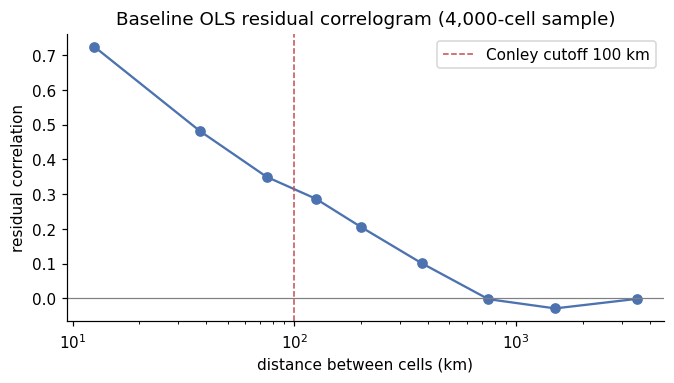

,0,1,2,3,4,5,6,7,8
bin_km,0-25,25-50,50-100,100-150,150-250,250-500,500-1000,1000-2000,2000-5000
pairs,448,1351,4565,7160,19978,75143,204634,475121,1611318
corr,0.725,0.482,0.35,0.287,0.205,0.101,-0.002,-0.029,-0.001


In [10]:
from sklearn.metrics.pairwise import haversine_distances

rng = np.random.default_rng(SEED)
idx = rng.choice(len(base_data), 4000, replace=False)
coords = np.radians(base_data.loc[idx, ["lat", "long"]].to_numpy())

# residuals of the baseline fit (FitResult stores no residuals, so refit on the same estimation sample)
import pyfixest as pf
_fit = pf.feols(f.formula(), data=base_data, vcov="iid")
resid = np.asarray(_fit.resid())
u = (resid[idx] - resid[idx].mean()) / resid[idx].std()

D = haversine_distances(coords) * 6371.0
iu = np.triu_indices(len(idx), 1)
d, prod = D[iu], (u[:, None] * u[None, :])[iu]
bins = np.array([0, 25, 50, 100, 150, 250, 500, 1000, 2000, 5000])
cor = [prod[(d >= a) & (d < b)].mean() for a, b in zip(bins[:-1], bins[1:])]
npairs = [((d >= a) & (d < b)).sum() for a, b in zip(bins[:-1], bins[1:])]

fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot((bins[:-1] + bins[1:]) / 2, cor, "o-", color="#4C72B0")
ax.axhline(0, color="grey", lw=0.8); ax.axvline(100, color="#C44E52", ls="--", lw=1, label="Conley cutoff 100 km")
ax.set(xscale="log", xlabel="distance between cells (km)", ylabel="residual correlation",
       title="Baseline OLS residual correlogram (4,000-cell sample)"); ax.legend()
plt.show()
pd.DataFrame({"bin_km": [f"{a}-{b}" for a, b in zip(bins[:-1], bins[1:])], "pairs": npairs, "corr": np.round(cor, 3)}).T

**What the correlogram estimates.** For the standardized residuals $z_i$, each point is the mean of $z_iz_j$ over all pairs
in a distance bin, i.e. an estimate of $\operatorname{Corr}(u_i,u_j)$ as a function of $d_{ij}$. This is the empirical
counterpart of the off-diagonal of $\Omega$ that iid and HC1 set to zero. It is closely related to Moran's I (one
distance band) and to the empirical variogram used in geostatistics, $\gamma(d)=\sigma^2(1-\rho(d))$.

**How to read it.**
* If the residuals were independent, the correlation would be about 0 at every distance. A clearly positive correlation at
  short range is the signature that iid/HC1 SEs are too small and that Conley SEs are needed.
* The distance at which the curve reaches 0 is the natural **cutoff**. The 100 km cutoff is a choice made in the paper.
  In the run shown, the correlation is still about 0.3 at 100–150 km and about 0.1 at 250–500 km, and reaches 0 only
  beyond about 500 km. With a uniform 100 km kernel all of this longer-range correlation is ignored, so **even the
  Conley SEs are probably optimistic**. A cutoff of a few hundred km would be a natural sensitivity check (it is
  computationally heavier, because the neighbour count grows with the square of the radius).
* The plot shows only $\rho_u$. The other half of the Moulton product, $\rho_x$, is the spatial smoothness of the debts
  themselves. It is high too (see the maps in Part B), which is why the correction is large.
* The estimate is noisy in the shortest bins, which have few pairs in a 4,000-cell sample.

In [11]:
with Timer("baseline OLS (HC1)"):
    base_hc1, _ = ols.fit_model("model_baseline", f, df_ok, "HC1")
fits_se = {"iid": base_iid, "HC1": base_hc1}
if RUN_CONLEY:
    with Timer("baseline OLS (Conley 100 km)"):
        base_conley, _ = ols.fit_model("model_baseline", f, df_ok, "conley")
    fits_se["Conley 100 km"] = base_conley

se_tab = pd.DataFrame({k: pd.Series(r.se, index=r.coefnames)[TREAT] for k, r in fits_se.items()})
se_tab.index = se_tab.index.map(LABEL)
se_tab.insert(0, "beta", pd.Series(base_iid.coef, index=base_iid.coefnames)[TREAT].values)
if RUN_CONLEY:
    se_tab["Conley / iid"] = se_tab["Conley 100 km"] / se_tab["iid"]
    se_tab["t (Conley)"] = se_tab["beta"] / se_tab["Conley 100 km"]
se_tab.round(4)

[baseline OLS (HC1)] 1.9 s
[baseline OLS (Conley 100 km)] 13.3 s


,beta,iid,HC1,Conley 100 km,Conley / iid,t (Conley)
Erosion,0.0443,0.0021,0.0023,0.0219,10.1999,2.0258
Compaction,0.0570,0.0012,0.0012,0.0125,10.7948,4.5553
SOC,0.0073,0.0014,0.0013,0.0107,7.5372,0.6800
Soil water,0.0330,0.0013,0.0014,0.0105,8.1447,3.1493
Tree cover,0.0335,0.0018,0.0019,0.0159,8.8160,2.1143


In [17]:
# variance inflation and implied effective sample size (A3.4): VIF = (SE / SE_iid)^2, n_eff = n / VIF
if RUN_CONLEY:
    n_obs = base_iid.nobs
    vif = pd.DataFrame({
        "HC1 / iid (SE)": se_tab["HC1"] / se_tab["iid"],
        "VIF Conley": (se_tab["Conley 100 km"] / se_tab["iid"]) ** 2,
    })
    vif["n_eff"] = (n_obs / vif["VIF Conley"]).round(-1).astype(int)
    vif["t (iid)"] = se_tab["beta"] / se_tab["iid"]
    vif["t (Conley)"] = se_tab["t (Conley)"]
    print(f"n = {n_obs:,} cells")
    display(vif.round(2))

n = 405,084 cells


,HC1 / iid (SE),VIF Conley,n_eff,t (iid),t (Conley)
Erosion,1.07,104.04,3890,20.66,2.03
Compaction,1.04,116.53,3480,49.17,4.56
SOC,0.94,56.81,7130,5.12,0.68
Soil water,1.06,66.34,6110,25.65,3.15
Tree cover,1.04,77.72,5210,18.64,2.11


The point estimates are identical across the three columns: only the variance estimator changes. The
**Conley / iid** ratio shows how much spatial correlation inflates the uncertainty. The paper's
inference (Fig. 2) uses the Conley SEs.

**Reading the two tables against the theory.**
* **HC1 ≈ iid** (ratio ≈ 1). Heteroskedasticity, i.e. the diagonal of $\Omega$, is a minor issue for these coefficients.
* **Conley ≈ 8–11 × iid.** In variance terms that is a VIF of about 60–120, i.e. $(m-1)\rho_x\rho_u$ of that order with $m\approx300$
  neighbours. The off-diagonal (spatial) part of $\Omega$ dominates.
* **$n_{\text{eff}}$ of a few thousand.** For inference, the 570k cells are worth only a few thousand independent observations.
* **Consequences for the conclusions.** t-statistics shrink from 5–50 (iid) to about 0.7–4.6 (Conley). Compaction and soil water stay
  clearly significant, erosion and tree cover are borderline (t ≈ 2), and SOC is not distinguishable from 0. Because the
  correlogram is still positive beyond 100 km (above), the true uncertainty is probably larger still.

## A4. The control ladder (Fig. 2)

The same five debts are estimated under increasingly rich control sets:

1. **no controls**: raw conditional association among the debts only
2. **natural**: + climate, climate change, terrain, soil (pre-determined confounders)
3. **natural + adaptation**: + inputs and irrigation (possible mediators)
4. **full**: + socioeconomics (possible mediators and confounders)

*Rationale.* Large swings between 1 and 2 show that geography confounds the raw association. Stability
from 2 → 4 suggests that the "bad control" concern is not first-order.

In [12]:
ladder = {
    "no controls": ols.make_formula(controls=[]),
    "natural": ols.make_formula(controls=ols.natural_controls),
    "natural + adaptation": ols.make_formula(controls=ols.natural_controls + dc.CONTROLS_adaptation_LOG),
    "full": ols.make_formula(controls=ols.natural_controls + dc.CONTROLS_adaptation_LOG + dc.CONTROLS_socioeconomic_LOG),
}
vc = "conley" if RUN_CONLEY else "HC1"
ladder_fits = {}
for name, spec in ladder.items():
    with Timer(f"ladder: {name} ({vc})"):
        ladder_fits[name], _ = ols.fit_model(name, spec, df_ok, vc)

[ladder: no controls (conley)] 9.2 s
[ladder: natural (conley)] 20.3 s
[ladder: natural + adaptation (conley)] 26.6 s
[ladder: full (conley)] 24.2 s


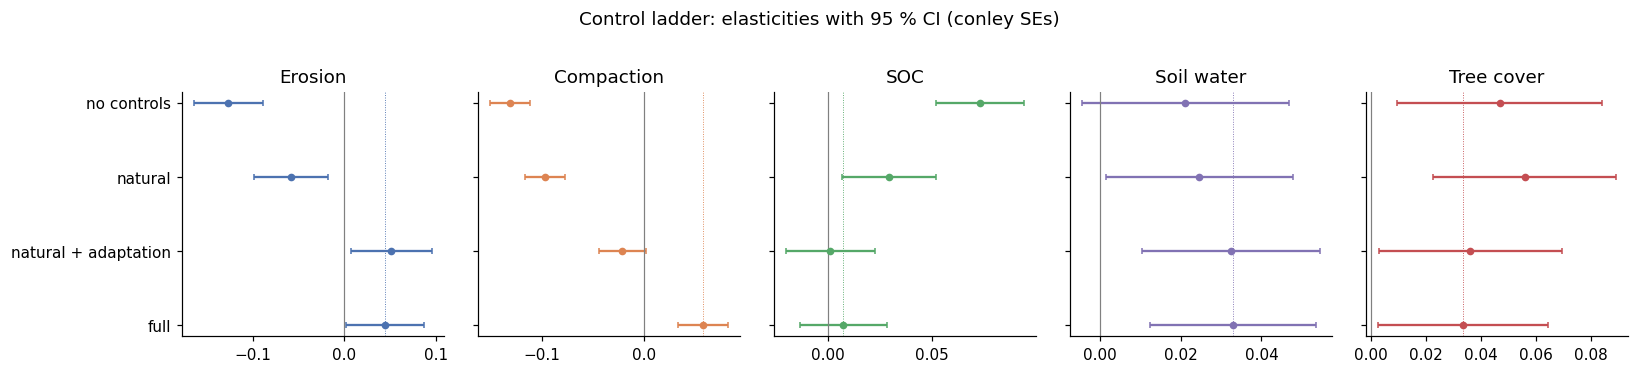

model,no controls,natural,natural + adaptation,full
debt,,,,
Compaction,-0.1312,-0.0968,-0.0213,0.0570
Erosion,-0.1264,-0.0583,0.0513,0.0443
SOC,0.0731,0.0293,0.0010,0.0073
Soil water,0.0211,0.0247,0.0324,0.0330
Tree cover,0.0468,0.0559,0.0361,0.0335


In [13]:
def coef_plot(fits: dict, title: str, ref: str | None = None):
    # one panel per debt; one row per model; point = beta, bar = 95 % CI
    tabs = pd.concat([tidy_treat(r, m) for m, r in fits.items()])
    models = list(fits)
    fig, axes = plt.subplots(1, 5, figsize=(15, 0.42 * len(models) + 1.6), sharey=True)
    for ax, t in zip(axes, TREAT):
        sub = tabs[tabs["debt"] == LABEL[t]].set_index("model").loc[models]
        y = np.arange(len(models))[::-1]
        ax.errorbar(sub["estimate"], y, xerr=[sub["estimate"] - sub["conf_low"], sub["conf_high"] - sub["estimate"]],
                    fmt="o", color=COLORS[t], ms=4, capsize=2)
        ax.axvline(0, color="grey", lw=0.8)
        if ref is not None:
            ax.axvline(sub.loc[ref, "estimate"], color=COLORS[t], lw=0.6, ls=":")
        ax.set_title(LABEL[t]); ax.set_yticks(y); ax.set_yticklabels(models)
    fig.suptitle(title, y=1.02); plt.tight_layout(); plt.show()
    return tabs

ladder_tab = coef_plot(ladder_fits, f"Control ladder: elasticities with 95 % CI ({vc} SEs)", ref="full")
ladder_tab.pivot(index="debt", columns="model", values="estimate")[list(ladder_fits)].round(4)

## A5. Robustness checks (Supp. Figs. 3–5)

Each check changes one aspect of the baseline and asks whether the elasticities survive:

| Check | Change | Threat addressed |
|---|---|---|
| winsorized | all numeric variables capped at their 2.5 / 97.5 % quantiles | a few extreme cells drive the slope |
| long/lat polynomial | + long, lat, long², lat², long·lat | smooth large-scale spatial gradients |
| without SoilGrids | − clay/sand/silt | collinearity with the soil debts |
| crop-type controls | + 10 dominant-crop dummies | crop composition (rice vs. maize gaps differ) |
| + field size, soil depth, soil N, water table, roads, travel time, ag. expenditure, economic freedom | one extra covariate each | specific omitted variables |
| without machinery | − machinery | machinery as a possible bad control |

iid SEs are used here because the comparison is about the point estimates. The script saves Conley variants for
the main checks.

[robustness fits] 40.0 s


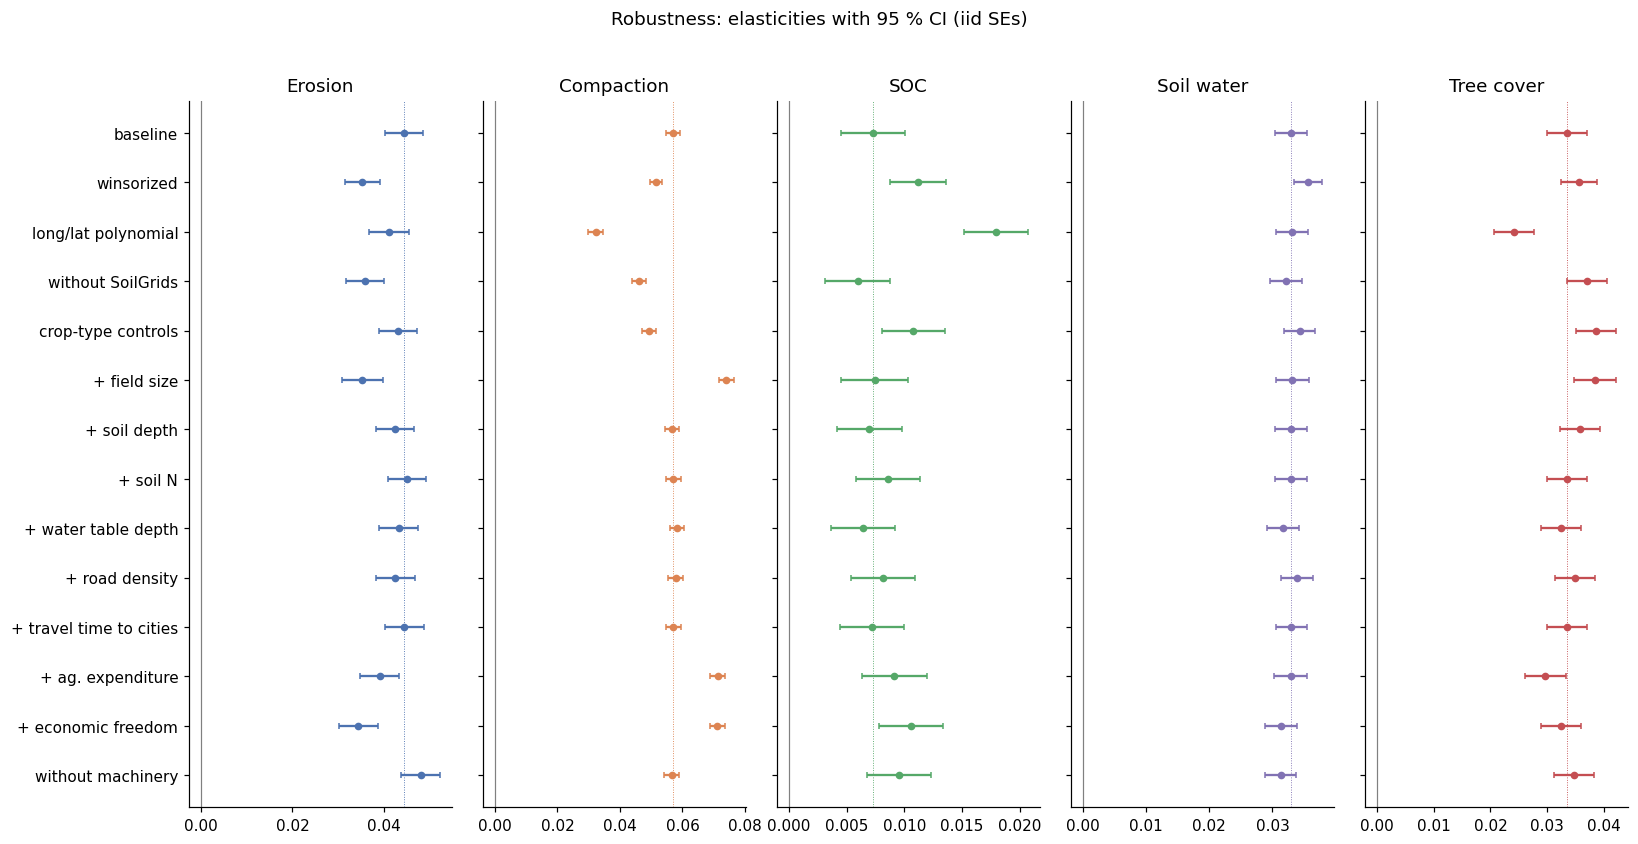

,n,R²
baseline,405084.0,0.331
winsorized,405084.0,0.373
long/lat polynomial,405084.0,0.345
without SoilGrids,405084.0,0.319
crop-type controls,405084.0,0.351
+ field size,368423.0,0.348
+ soil depth,405083.0,0.331
+ soil N,405084.0,0.331
+ water table depth,405084.0,0.332
+ road density,405079.0,0.332


In [14]:
L = dc.LOG_SUFFIX
df_ok_winsor = pd.DataFrame({c: ols.winsorize(df_ok[c]) for c in df_ok.columns})
f_crop = f.add(*dc.crop_type_dummy_vars)

robust_specs = {
    "baseline": (f, df_ok),
    "winsorized": (f, df_ok_winsor),
    "long/lat polynomial": (f.add("long", "lat", ols.sq("long"), ols.sq("lat"), "long:lat"), df_ok),
    "without SoilGrids": (f.drop(*dc.CONTROLS_environment_soilGrid_LOG), df_ok),
    "crop-type controls": (f_crop, df_ok),
    "+ field size": (f.add(dc.ROBUSTNESS_EXTRA_CATEGORICAL), df_ok),
    "+ soil depth": (f.add("soilDepth__mean" + L), df_ok),
    "+ soil N": (f.add("nitrogen__sum" + L), df_ok),
    "+ water table depth": (f.add("waterTableDepth" + L), df_ok),
    "+ road density": (f.add("roadDens__mean" + L), df_ok),
    "+ travel time to cities": (f.add("travel_time_to_cities" + L), df_ok),
    "+ ag. expenditure": (f.add("agriShareOfGovtExpend_ca2010" + L, "agriOrientIdxForGovtExpend_ca2010" + L), df_ok),
    "+ economic freedom": (f.add("efw_ca2010" + L), df_ok),
    "without machinery": (f.drop("machinery_ca2010" + L), df_ok),
}
robust_fits = {}
with Timer("robustness fits"):
    for name, (spec, data) in robust_specs.items():
        robust_fits[name], _ = ols.fit_model(name, spec, data, "iid")

robust_tab = coef_plot(robust_fits, "Robustness: elasticities with 95 % CI (iid SEs)", ref="baseline")
pd.DataFrame({m: {"n": r.nobs, "R²": round(r.r2, 3)} for m, r in robust_fits.items()}).T

## A6. Which side of the gap moves? Actual vs attainable yield (Fig. 3, Supp. Fig. 6)

Since $YG \approx (Y^{att}-Y^{act})/Y^{att}$, a larger gap can come from **lower actual yields** or from a
**higher attainable benchmark**. Re-estimating the baseline with each component as the outcome separates the two:

* $\beta^{act}_k < 0$ means degradation lowers realised yields (the mechanism one would expect).
* $\beta^{att}_k \approx 0$ means the benchmark is unaffected, so the gap reflects real losses.

(Recall that actual and attainable yield use the `x - min + 1` rescaling, so their elasticities are not on the same scale as the yield-gap ones.)

[decomposition fits] 10.5 s


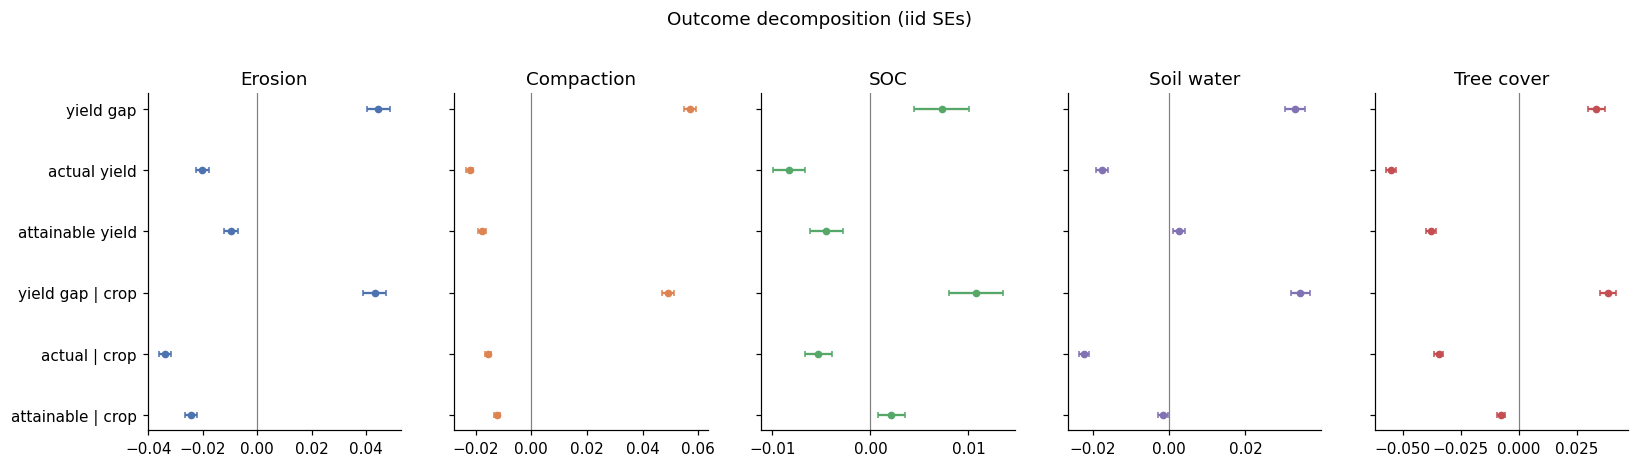

model,yield gap,actual yield,attainable yield,yield gap | crop,actual | crop,attainable | crop
debt,,,,,,
Compaction,0.0570,-0.0221,-0.0176,0.0492,-0.0156,-0.0124
Erosion,0.0443,-0.0202,-0.0097,0.0431,-0.0339,-0.0242
SOC,0.0073,-0.0083,-0.0045,0.0108,-0.0053,0.0021
Soil water,0.0330,-0.0175,0.0026,0.0343,-0.0222,-0.0016
Tree cover,0.0335,-0.0550,-0.0377,0.0387,-0.0345,-0.0076


In [15]:
actual, attain = "actualYieldGerberRay" + L, "attainableYieldGerberRay" + L
decomp_fits = {}
with Timer("decomposition fits"):
    for name, spec in {
        "yield gap": f, "actual yield": f.with_outcome(actual), "attainable yield": f.with_outcome(attain),
        "yield gap | crop": f_crop, "actual | crop": f_crop.with_outcome(actual), "attainable | crop": f_crop.with_outcome(attain),
    }.items():
        decomp_fits[name], _ = ols.fit_model(name, spec, df_ok, "iid")
decomp_tab = coef_plot(decomp_fits, "Outcome decomposition (iid SEs)")
decomp_tab.pivot(index="debt", columns="model", values="estimate")[list(decomp_fits)].round(4)

## A7. Nonlinearity and interactions: average marginal effects

A linear-in-logs model forces a constant elasticity. Three richer models relax that:

* **quadratic**: + $(\log D_k)^2$ for each debt
* **debt interactions**: + all 26 products of 2–5 debts (does joint degradation compound?)
* **debt × adaptation**: + the above and the 40 debt × adaptation products (does management buffer degradation?)

In these models the effect of $D_1$ varies across cells, so the coefficients are not comparable to
$\beta_1$. The **average marginal effect** is:

$$\text{AME}_1 = \frac1n\sum_i \frac{\partial \widehat{\log YG}_i}{\partial \log D_{i1}} = \bar g_1'\hat\beta,
\qquad \bar g_1 = \frac1n\sum_i \frac{\partial\, \text{design row}_i}{\partial \log D_{i1}}.$$

The AME is linear in $\hat\beta$, so the delta-method SE $\sqrt{\bar g_1'\hat V\bar g_1}$ is exact. `avg_slopes`
differentiates each term analytically (plain, squared and `:` product terms). If the AMEs are close to the linear $\hat\beta$, the
headline elasticity is a good summary despite the nonlinearity.

[nonlinear: quadratic] 7.3 s
[nonlinear: debt interactions] 7.9 s
[nonlinear: debt × adaptation] 5.4 s


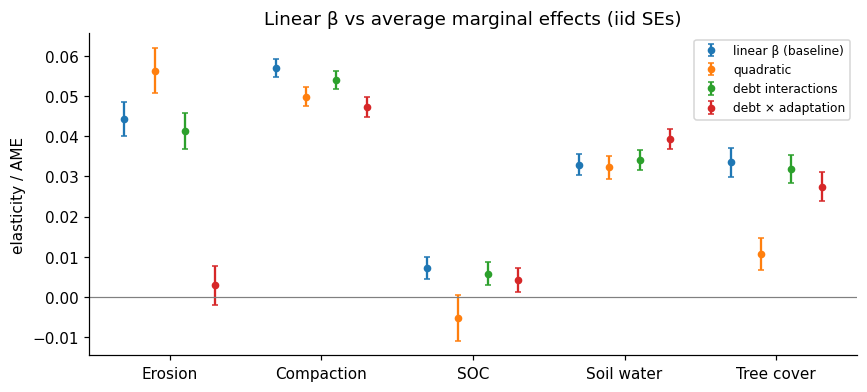

model,linear β (baseline),quadratic,debt interactions,debt × adaptation
term,,,,
Compaction,0.0570,0.0499,0.0540,0.0474
Erosion,0.0443,0.0563,0.0413,0.0029
SOC,0.0073,-0.0052,0.0058,0.0042
Soil water,0.0330,0.0323,0.0340,0.0393
Tree cover,0.0335,0.0107,0.0319,0.0275


In [18]:
if RUN_AVG_SLOPES:
    import itertools
    inter_LD = [":".join(c) for i in range(2, 6) for c in itertools.combinations(TREAT, i)]
    inter_LD_adapt = [f"{t}:{a}" for t in TREAT for a in dc.CONTROLS_adaptation_LOG]
    nonlin = {
        "quadratic": f.add(*[ols.sq(t) for t in TREAT]),
        "debt interactions": f.add(*inter_LD),
        "debt × adaptation": f.add(*inter_LD, *inter_LD_adapt),
    }
    ame_rows, nonlin_fits = [], {}
    for name, spec in nonlin.items():
        with Timer(f"nonlinear: {name}"):
            res, data = ols.fit_model(name, spec, df_ok, "iid")
            a = avg_slopes(res, data, TREAT); a["model"] = name
            ame_rows.append(a); nonlin_fits[name] = res
    lin = tidy_treat(base_iid, "linear β (baseline)").rename(columns={"debt": "term"})
    ame = pd.concat(ame_rows); ame["term"] = ame["term"].map(LABEL)
    ame_all = pd.concat([lin[["model", "term", "estimate", "conf_low", "conf_high"]],
                         ame[["model", "term", "estimate", "conf_low", "conf_high"]]])

    models = ame_all["model"].unique().tolist()
    fig, ax = plt.subplots(figsize=(9, 3.8))
    w = 0.8 / len(models)
    for j, m in enumerate(models):
        s = ame_all[ame_all["model"] == m].set_index("term").loc[[LABEL[t] for t in TREAT]]
        x = np.arange(5) + (j - (len(models) - 1) / 2) * w
        ax.errorbar(x, s["estimate"], yerr=[s["estimate"] - s["conf_low"], s["conf_high"] - s["estimate"]],
                    fmt="o", ms=4, capsize=2, label=m)
    ax.axhline(0, color="grey", lw=0.8); ax.set_xticks(range(5)); ax.set_xticklabels([LABEL[t] for t in TREAT])
    ax.set_ylabel("elasticity / AME"); ax.set_title("Linear β vs average marginal effects (iid SEs)"); ax.legend(fontsize=8)
    plt.show()
    display(ame_all.pivot(index="term", columns="model", values="estimate")[models].round(4))
else:
    print("RUN_AVG_SLOPES=False: skipped")

## A8. Save the OLS results

The results are written with the script's own `save_result` (as a `.pkl` `FitResult` plus a `_coefs.csv`) under
`data/processed/models_py/{main_10km,hc1,conley_100km}/`. These are the same names that the script produces.

In [19]:
from dataclasses import replace
script_names = {"no controls": "model_no_controls", "natural": "model_natural_controls",
                "natural + adaptation": "model_natural_adaptation_controls", "full": "model_full_controls",
                "baseline": "model_baseline", "winsorized": "model_winsorized",
                "long/lat polynomial": "model_long_lat_polynomial", "without SoilGrids": "model_without_soilgrid_controls",
                "crop-type controls": "model_yield_gap_crop_type_controls", "+ field size": "model_field_size_control",
                "+ soil depth": "model_soil_depth_control", "+ soil N": "model_soil_n_control",
                "+ water table depth": "model_water_table_depth_control", "+ road density": "model_road_density_control",
                "+ travel time to cities": "model_travel_time_to_cities_control",
                "+ ag. expenditure": "model_agricultural_expenditure_control",
                "+ economic freedom": "model_economic_freedom_control", "without machinery": "model_without_machinery_control",
                "actual yield": "model_actual_yield", "attainable yield": "model_attainable_yield",
                "actual | crop": "model_actual_yield_crop_type_controls",
                "attainable | crop": "model_attainable_yield_crop_type_controls"}

ols.save_result(base_hc1, OLS_OUT["hc1"], "model_baseline")
if RUN_CONLEY:
    ols.save_result(base_conley, OLS_OUT["conley_100km"], "model_baseline")
    for k, r in ladder_fits.items():
        ols.save_result(replace(r, name=script_names[k]), OLS_OUT["conley_100km"], script_names[k])
for k, r in {**robust_fits, **{k: v for k, v in decomp_fits.items() if k in script_names}}.items():
    ols.save_result(replace(r, name=script_names[k]), OLS_OUT["main_10km"], script_names[k])
if RUN_AVG_SLOPES:
    for (k, r), a in zip(nonlin_fits.items(), ame_rows):
        stem = {"quadratic": "model_quadratic_land_degradation", "debt interactions": "model_interaction_land_degradation",
                "debt × adaptation": "model_interaction_land_degradation_adaptation"}[k]
        ols.save_result(replace(r, name=stem), OLS_OUT["main_10km"], stem)
        a.to_csv(OLS_OUT["main_10km"] / f"{stem}_average_slope.csv", index=False)

  saved hc1/model_baseline  (n=405084, vcov=HC1)
  saved conley_100km/model_baseline  (n=405084, vcov=conley_100km)
  saved conley_100km/model_no_controls  (n=409487, vcov=conley_100km)
  saved conley_100km/model_natural_controls  (n=409469, vcov=conley_100km)
  saved conley_100km/model_natural_adaptation_controls  (n=406899, vcov=conley_100km)
  saved conley_100km/model_full_controls  (n=405084, vcov=conley_100km)
  saved main_10km/model_baseline  (n=405084, vcov=iid)
  saved main_10km/model_winsorized  (n=405084, vcov=iid)
  saved main_10km/model_long_lat_polynomial  (n=405084, vcov=iid)
  saved main_10km/model_without_soilgrid_controls  (n=405084, vcov=iid)
  saved main_10km/model_yield_gap_crop_type_controls  (n=405084, vcov=iid)
  saved main_10km/model_field_size_control  (n=368423, vcov=iid)
  saved main_10km/model_soil_depth_control  (n=405083, vcov=iid)
  saved main_10km/model_soil_n_control  (n=405084, vcov=iid)
  saved main_10km/model_water_table_depth_control  (n=405084, vco

---
# Part B: causal forests and heterogeneous effects

## B1. Theory

**Estimand.** The yield gap follows a *partially linear model with a heterogeneous slope*:

$$Y_i = \tau(X_i)\,W_i + m(X_i) + \varepsilon_i,$$

where $W$ is one debt (continuous) and $X$ holds all controls plus the *other four* debts. $\tau(x)$ is the
**conditional average treatment effect (CATE)**: the expected change in yield-gap **percentage points
per one raw unit** of the debt, for a cell with characteristics $x$. With a continuous $W$ it is a local
average slope, not a binary contrast.

**Step 1: Robinson / R-learner residualization.** Taking expectations given $X$ and subtracting gives

$$\underbrace{Y_i - m^*(X_i)}_{\tilde Y_i} = \tau(X_i)\,\underbrace{(W_i - e(X_i))}_{\tilde W_i} + \varepsilon_i,
\qquad m^*(x)=E[Y\mid X=x],\; e(x)=E[W\mid X=x].$$

The unknown baseline $m(X)$ drops out. grf estimates $\hat m^*$ and $\hat e$ with regression forests and uses
their **out-of-bag** predictions ("local centering"). This orthogonalized moment is *Neyman-orthogonal*: first-order
errors in $\hat m^*,\hat e$ do not bias $\hat\tau$. Here we can also inspect *what part of $W$ is not explained by X*,
which is the variation that identifies $\tau$.

**Step 2: Generalized random forest (Athey, Tibshirani & Wager 2019).** For a target cell $x$, the forest defines
adaptive weights $\alpha_i(x)$ (the share of trees in which cell $i$ falls into the same leaf as $x$) and solves the local moment

$$\sum_i \alpha_i(x)\,\big(\tilde Y_i - \tau(x)\tilde W_i - b(x)\big)\binom{\tilde W_i}{1} = 0
\;\;\Rightarrow\;\; \hat\tau(x) = \frac{\sum_i \alpha_i(x)(\tilde W_i-\bar{\tilde W}_\alpha)(\tilde Y_i-\bar{\tilde Y}_\alpha)}{\sum_i \alpha_i(x)(\tilde W_i-\bar{\tilde W}_\alpha)^2},$$

i.e. a *weighted local regression of $\tilde Y$ on $\tilde W$*. Two design choices make it a valid estimator:

* **Gradient-based ("het") splitting.** Trees split to maximise heterogeneity in $\tau$, not to predict $Y$.
* **Honesty.** Each tree chooses its splits on one half of its subsample and estimates the leaf values on the other half. This gives consistent, asymptotically normal CATEs.

**Rationale for the paper's choices**
* *Raw scale.* Trees are invariant to monotone transforms of $X$, so logging $X$ is pointless. $Y$ and $W$ are kept in natural units, so the CATE is in "pp of gap per unit of debt", which the loss calculation needs.
* *Other debts in X.* Each CATE for debt $k$ holds the other four fixed, as the joint OLS does, and it lets the effect of $k$ depend on them (e.g. erosion may hurt more where SOC is already depleted).
* *Same identifying assumption as OLS* (unconfoundedness given $X$). The forest relaxes the **functional form**, not the identification.

* *Inference under spatial dependence.* grf's (and econml's) CATE confidence intervals come from the variance across
  subforests (the "little bags" of `ci.group.size`). That derivation assumes **independent observations**. With the spatial
  correlation documented in A3, neighbouring cells are not independent draws, so the pointwise CATE intervals are too
  narrow, for the same reason that iid/HC1 SEs are too narrow in Part A.

## B2. Data preparation

This mirrors `prepare_data()` in `02_fit_causal_forests.py`:
1. Keep the raw outcome, treatments, controls and crop dummies, then drop every row with any NA (`tidyr::drop_na`).
2. Build `X_base` from all numeric controls, a one-hot encoding of soil type (one column per level) and the 10 crop dummies.

It reuses the `df_raw` loaded above instead of re-reading the `.rds`.

In [20]:
keep = list(dict.fromkeys(["long", "lat", dc.OUTCOME_RAW, *dc.TREATMENTS_RAW,
                           "attainableYieldGerberRay", "actualYieldGerberRay",
                           *dc.crop_type_dummy_vars, *cfs.X_BASE_NUMERIC, dc.CONTROLS_environment_soilType]))
df_cf = df_raw.dropna(subset=keep)[keep + [v + dc.LOG_SUFFIX for v in [dc.OUTCOME_RAW, *dc.TREATMENTS_RAW]]].reset_index(drop=True)
for c in dc.crop_type_dummy_vars:
    df_cf[c] = cfs._as_int(df_cf[c])
print(f"complete-case CF sample: {len(df_cf):,} cells  (R CATE tables have 405,084 rows)")

if CF_SCALE == "log":
    # swap Y and the five debts (as W, and the other four as covariates) for their __rescaled__log versions
    for v in [dc.OUTCOME_RAW, *dc.TREATMENTS_RAW]:
        df_cf[v] = df_cf[v + dc.LOG_SUFFIX]
    print("CF_SCALE='log': Y and debts are on the __rescaled__log scale")

soil_hot = pd.get_dummies(df_cf[dc.CONTROLS_environment_soilType].astype("category"),
                          prefix=dc.CONTROLS_environment_soilType, prefix_sep="", dtype=float)
X_base = pd.concat([df_cf[cfs.X_BASE_NUMERIC].astype(float), soil_hot,
                    df_cf[dc.crop_type_dummy_vars].astype(float)], axis=1)
print(f"X_base: {X_base.shape[1]} columns = {len(cfs.X_BASE_NUMERIC)} numeric + {soil_hot.shape[1]} soil-type + "
      f"{len(dc.crop_type_dummy_vars)} crop dummies  (+4 other debts per forest)")

if N_SUB is not None and N_SUB < len(df_cf):
    sub = np.sort(np.random.default_rng(SEED).choice(len(df_cf), N_SUB, replace=False))
    df_cf, X_base = df_cf.iloc[sub].reset_index(drop=True), X_base.iloc[sub].reset_index(drop=True)
    print(f"DEMO: random subsample of {len(df_cf):,} cells")
Y = df_cf[dc.OUTCOME_RAW].to_numpy(float)

complete-case CF sample: 405,084 cells  (R CATE tables have 405,084 rows)
X_base: 62 columns = 40 numeric + 12 soil-type + 10 crop dummies  (+4 other debts per forest)
DEMO: random subsample of 50,000 cells


## B3. One forest, opened up: soil erosion

Before looping over all five debts, the three stages of `causal_forest()` are run by hand for erosion, so that
each intermediate object can be inspected.

### Hyperparameters (grf → econml mapping)

| grf (R) | econml | value |
|---|---|---|
| `num.trees` | `n_estimators` | 2000 (full) / `NUM_TREES` (demo) |
| `sample.fraction` | `max_samples` | 0.5 |
| `mtry` = min(⌈√p + 20⌉, p) | `max_features` | `grf_mtry(p)` |
| `min.node.size` | `min_samples_leaf` | 5 |
| `honesty` | `honest` | True |
| `alpha` = 0.05 | `min_balancedness_tol` | 0.45 |
| `ci.group.size` = 2 | `subforest_size` | 4 |
| nuisance forests | `RegressionForest` | max(50, trees/4) trees, OOB predictions |

In [ ]:
from econml.grf import CausalForest, RegressionForest

D_var = "soilErosionDebt"
W = df_cf[D_var].to_numpy(float)
X_df = pd.concat([X_base, df_cf[[t for t in dc.TREATMENTS_RAW if t != D_var]].astype(float)], axis=1)
X = X_df.to_numpy()
p = X.shape[1]
common = dict(min_samples_leaf=5, max_features=cfs.grf_mtry(p), max_samples=0.5,
              min_balancedness_tol=0.45, honest=True, n_jobs=NUM_THREADS, random_state=SEED)
n_nuis = max(52, (NUM_TREES // 4) // 4 * 4)
print(f"p = {p}, mtry = {cfs.grf_mtry(p)}, nuisance trees = {n_nuis}, CF trees = {NUM_TREES // 4 * 4}")

### Stage 1: nuisance models (local centering)

Two honest regression forests give OOB predictions of $E[Y|X]$ and $E[W|X]$. The diagnostics are:
* **$R^2$ of Ŷ**: how much of the yield gap the controls explain on their own.
* **$R^2$ of Ŵ**: how predictable the debt is from X. If this is close to 1, little independent variation in $W$ is left
  (an *overlap* problem), and the CATEs would be noisy and extrapolated.

In [ ]:
with Timer("nuisance forests"):
    Y_hat = RegressionForest(n_estimators=n_nuis, inference=False, **common).fit(X, Y).oob_predict(X).ravel()
    W_hat = RegressionForest(n_estimators=n_nuis, inference=False, **common).fit(X, W).oob_predict(X).ravel()
Y_t, W_t = Y - Y_hat, W - W_hat
r2 = lambda y, yh: 1 - np.var(y - yh) / np.var(y)
print(f"OOB R²  E[Y|X]: {r2(Y, Y_hat):.3f}    E[W|X]: {r2(W, W_hat):.3f}")
print(f"residual SD of W: {W_t.std():.4g}  (raw SD {W.std():.4g}) -> {100 * W_t.var() / W.var():.1f}% of Var(W) is left to identify tau")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hexbin(Y_hat, Y, gridsize=60, bins="log", cmap="Greys"); axes[0].set(xlabel="Ŷ (OOB)", ylabel="Y", title="outcome nuisance")
axes[1].hexbin(W_hat, W, gridsize=60, bins="log", cmap="Blues"); axes[1].set(xlabel="Ŵ (OOB)", ylabel="W", title="treatment nuisance (erosion)")
axes[2].hexbin(W_t, Y_t, gridsize=60, bins="log", cmap="Oranges"); axes[2].set(xlabel="W − Ŵ", ylabel="Y − Ŷ", title="centered data the CF sees")
plt.tight_layout(); plt.show()

**A global benchmark: the Robinson (residual-on-residual) slope.** Regressing $\tilde Y$ on $\tilde W$ with a single
coefficient gives a variance-weighted average of $\tau(x)$. This is the forest analogue of a "double ML" partially linear
estimate. It is a useful reference for the mean CATE.

*Note on the SE.* The HC1 SE printed here has the same limitation as in A3.3: it ignores the spatial correlation of
$\tilde Y$ and $\tilde W$, so it is too small, probably by a factor similar to the Conley/iid ratio in A3. Read the slope, not its SE.

In [ ]:
import statsmodels.api as sm
rob = sm.OLS(Y_t, sm.add_constant(W_t)).fit(cov_type="HC1")
print(f"Robinson slope (pp yield gap per unit erosion debt): {rob.params[1]:.4g}  (HC1 SE {rob.bse[1]:.3g})")

### Stage 2: the causal forest on centered data

`CausalForest(criterion="het")` splits on the gradient-based heterogeneity criterion and solves the local moment
above in each leaf. `fit_intercept=True` adds the $b(x)$ term.

In [ ]:
with Timer("causal forest (erosion)"):
    cf = CausalForest(n_estimators=max(4, NUM_TREES // 4 * 4), criterion="het", fit_intercept=True,
                      inference=True, subforest_size=4, **common)
    cf.fit(X, W_t.reshape(-1, 1), Y_t)
    cate = cf.oob_predict(X).ravel()          # R: predict(cf)$predictions (out-of-bag)

print(f"mean CATE = {cate.mean():.4g}   median = {np.median(cate):.4g}   share > 0: {100 * (cate > 0).mean():.1f}%")
print(f"Robinson slope = {rob.params[1]:.4g}  (variance-weighted average, comparable to the mean CATE)")

### Stage 3: inspecting the heterogeneity

* **Distribution of OOB CATEs.** Is there real spread, or does it just scatter around the mean?
* **Variable importance.** Which covariates the forest splits on most (weighted by depth). This is a *descriptive* measure of where heterogeneity is found, not a causal statement.
* **Best linear projection (BLP)** of $\tau(x)$ on a few covariates, estimated orthogonally:
  regress $\tilde Y$ on $\tilde W$ and $\tilde W\cdot(x_j - \bar x_j)$. The interaction coefficients tell how $\tau$ changes with
  $x_j$, with valid SEs (as in `grf::best_linear_projection`).

  *Caveat:* the BLP SEs below are HC1, so, as in A3, they ignore spatial correlation and overstate precision.
  Treat them as a ranking of moderators rather than as formal tests.

In [ ]:
imp = pd.Series(cf.feature_importances_, index=X_df.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
lo, hi = np.percentile(cate, [0.5, 99.5])
axes[0].hist(np.clip(cate, lo, hi), bins=80, color=COLORS[D_var])
axes[0].axvline(0, color="k", lw=0.8); axes[0].axvline(cate.mean(), color="#C44E52", ls="--", label=f"mean {cate.mean():.3g}")
axes[0].set(title="OOB CATE: erosion (pp yield gap / unit debt)", xlabel="CATE"); axes[0].legend()
imp.head(15)[::-1].plot.barh(ax=axes[1], color="#4C72B0"); axes[1].set_title("CF split importance (top 15)")
plt.tight_layout(); plt.show()

In [ ]:
blp_vars = ["aridity__mean", "clay__mean", "soilOrganicCarbonDebt", "irrigation_AEI_ha_end__mean", "hdi_ca2010__mean"]
Z = X_df[blp_vars].to_numpy()
Zs = (Z - Z.mean(0)) / Z.std(0)                       # standardised -> coefficients per 1 SD of x_j
design = np.column_stack([W_t, W_t[:, None] * Zs])
blp = sm.OLS(Y_t, sm.add_constant(design)).fit(cov_type="HC1")
pd.DataFrame({"coef": blp.params[1:], "se (HC1)": blp.bse[1:], "p": blp.pvalues[1:]},
             index=["tau at mean X"] + [f"Δtau per +1 SD {v}" for v in blp_vars]).round(4)

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for ax, v in zip(axes, ["aridity__mean", "clay__mean", "soilOrganicCarbonDebt"]):
    x = X_df[v].to_numpy()
    q = pd.qcut(x, 20, duplicates="drop")
    g = pd.DataFrame({"x": x, "c": cate}).groupby(q, observed=True).agg(x=("x", "mean"), c=("c", "mean"),
                                                                        lo=("c", lambda s: s.quantile(.25)), hi=("c", lambda s: s.quantile(.75)))
    ax.fill_between(g["x"], g["lo"], g["hi"], alpha=0.25, color=COLORS[D_var]); ax.plot(g["x"], g["c"], "o-", ms=3, color=COLORS[D_var])
    ax.axhline(0, color="grey", lw=0.8); ax.set(xlabel=v, ylabel="erosion CATE", title=f"CATE by {v} (ventiles; IQR band)")
plt.tight_layout(); plt.show()

## B4. All five forests

Now `causal_forest()` from the script runs for each debt. It does exactly the three stages above. The CATE tables
(`long, lat, CATE`) are written to `data/processed/causal_forest_py/`. Demo runs carry the suffix `_demo`, so they never
overwrite a full run.

In [ ]:
cates = {}
for key, (D, cate_col) in cfs.PROCESSES.items():
    Wk = df_cf[D].to_numpy(float)
    Xk = pd.concat([X_base, df_cf[[t for t in dc.TREATMENTS_RAW if t != D]].astype(float)], axis=1)
    with Timer(f"causal forest: {key}"):
        _, ck, _, _ = cfs.causal_forest(Xk.to_numpy(), Y, Wk, num_trees=NUM_TREES, min_node_size=5,
                                        num_threads=NUM_THREADS, seed=SEED)
    out = pd.DataFrame({"long": df_cf["long"], "lat": df_cf["lat"], "CATE": ck})
    out.to_csv(CF_OUT / f"cate_{key}_crop_type_controls{SUFFIX}.csv", index=False)
    if RUN_MODE == "full":
        out.to_parquet(CF_OUT / f"cate_{key}_crop_type_controls.parquet", index=False)
    cates[key] = ck
    print(f"   mean CATE {ck.mean():.4g} | share > 0: {100 * (ck > 0).mean():.1f}%")

cate_df = pd.DataFrame({"long": df_cf["long"], "lat": df_cf["lat"], **{f"CATE_{k}": v for k, v in cates.items()}})
cate_df.describe().T.round(4)

## B5. Comparison with the published R CATEs

The R replication CATEs (`data/processed/causal_forest/cate_*_crop_type_controls.csv.gz`) are merged by cell
(`long, lat`). Cell-by-cell identity is **not** expected:

* econml's GRF follows the same algorithm, but it has different random-number streams and split-search details, and it does not
  reproduce grf's `stabilize.splits` exactly
* in **demo** mode the forest is trained on a subsample with fewer trees, so its CATEs are noisier and smoother

What should agree: the **mean CATE** (≈ the ATE), the **sign**, and a clearly positive **correlation** across cells, i.e. the same
spatial pattern.

In [ ]:
R_DIR = path_processed("causal_forest")
key_round = lambda d: d.assign(long=d["long"].round(5), lat=d["lat"].round(5))
rows, merged = [], {}
for key in cfs.PROCESSES:
    r = key_round(pd.read_csv(R_DIR / f"cate_{key}_crop_type_controls.csv.gz")).rename(columns={"CATE": "R"})
    py = key_round(cate_df[["long", "lat", f"CATE_{key}"]].rename(columns={f"CATE_{key}": "Py"}))
    m = py.merge(r, on=["long", "lat"], how="inner"); merged[key] = m
    rows.append({"debt": key, "matched cells": len(m), "mean Py": m["Py"].mean(), "mean R": m["R"].mean(),
                 "Pearson r": m["Py"].corr(m["R"]), "Spearman ρ": m["Py"].corr(m["R"], method="spearman"),
                 "sign agreement %": 100 * (np.sign(m["Py"]) == np.sign(m["R"])).mean()})
cmp = pd.DataFrame(rows).set_index("debt")
cmp.round(4)

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(17, 3.6))
for ax, (key, m) in zip(axes, merged.items()):
    lo, hi = np.percentile(np.r_[m["Py"], m["R"]], [0.5, 99.5])
    ax.hexbin(m["R"].clip(lo, hi), m["Py"].clip(lo, hi), gridsize=50, bins="log", cmap="viridis")
    ax.plot([lo, hi], [lo, hi], "r--", lw=0.8)
    ax.set(title=f"{key}  r={cmp.loc[key, 'Pearson r']:.2f}", xlabel="R CATE", ylabel="Python CATE" if key == "erosion" else "")
plt.tight_layout(); plt.show()

### ⚠ What scale are the published R CATEs on?

`02_fit_causal_forests.R` fits the forests on the **raw** variables. The published R CATE tables, however, have
**similar spreads for all five debts** (SD ≈ 0.02–0.08), although the raw debts differ in scale by about 10⁵
(soil-water debt ≈ 0.007, tree-cover debt ≈ 1,200 on average). A CATE in "pp per raw unit" cannot look like that.

A check made while building this notebook (50k-cell demo, 200 trees, same subsample) found:

| debt | r(Python raw, R) | r(Python log, R) | R mean CATE | OLS log-log β |
|---|---|---|---|---|
| erosion | 0.12 | 0.38 | 0.013 | 0.044 |
| compaction | 0.16 | 0.27 | 0.009 | 0.057 |
| tree cover | 0.28 | 0.40 | 0.009 | 0.034 |

The R means are elasticity-sized, and the log-scale Python forest matches R about two to three times better. This suggests
that the published CATEs come from a forest fitted on `__rescaled__log` Y and W, i.e. they are **local elasticities**,
not "pp per unit". Set `CF_SCALE = "log"` to reproduce them. This matters downstream, because
`04_compute_loss_rasters_and_tables.R` must interpret the CATE units consistently. It is worth raising with the authors.

## B6. Maps of non-negative CATEs

The paper rasterizes each CATE table onto the yield-gap grid (`fun = "max"` for collisions), **sets negative
CATEs to 0**, and sums the five layers into an aggregate "degradation-attributable yield gap" surface.

*Rationale and caveat.* The loss accounting asks where degradation is associated with **larger** gaps. Clipping at 0 rules out
offsetting negative effects, so the summed layer leans upward, especially where CATEs are noisy around 0.

* **full** mode: the Python CATEs are rasterized with `rasterize_points_max` and written as Float32 DEFLATE GeoTIFFs to `causal_forest_py/rasterized/`.
* **demo** mode: only a subsample exists, so the Python CATEs are shown as points and the published R rasters are shown next to them for reference.

In [ ]:
import rasterio

def show_raster(ax, arr, transform, title, vmax=None):
    h, w = arr.shape
    ext = [transform.c, transform.c + transform.a * w, transform.f + transform.e * h, transform.f]
    vmax = vmax or np.nanpercentile(arr, 99)
    im = ax.imshow(arr, extent=ext, cmap="magma_r", vmin=0, vmax=vmax, interpolation="nearest")
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([]); ax.set_ylim(-60, 85)
    plt.colorbar(im, ax=ax, shrink=0.7)

with rasterio.open(path_raw("crop_yield", "yield_gap_2010_percent.tif")) as tmpl:
    transform, shape, crs = tmpl.transform, (tmpl.height, tmpl.width), tmpl.crs

if RUN_MODE == "full":
    out_dir = CF_OUT / "rasterized"; out_dir.mkdir(exist_ok=True)
    profile = dict(driver="GTiff", height=shape[0], width=shape[1], count=1, dtype="float32", crs=crs,
                   transform=transform, nodata=cfs.NA_FLAG, compress="deflate", tiled=True, blockxsize=512, blockysize=512)
    layers, total = {}, None
    for key in cfs.PROCESSES:
        rst = cfs.rasterize_points_max(cate_df["long"], cate_df["lat"], cate_df[f"CATE_{key}"].to_numpy(), transform, shape)
        nonneg = np.where(rst < 0, 0.0, rst)
        cfs.write_tif(nonneg, out_dir / f"cate_{key}_nonneg.tif", profile)
        layers[key] = nonneg; total = nonneg if total is None else total + nonneg
    cfs.write_tif(total, out_dir / "cate_sum_nonneg.tif", profile)
    layers["sum"] = total
    fig, axes = plt.subplots(2, 3, figsize=(17, 7))
    for ax, (k, a) in zip(axes.ravel(), layers.items()):
        show_raster(ax, a, transform, f"Python CATE ≥ 0: {k}")
    plt.tight_layout(); plt.show()
else:
    fig, axes = plt.subplots(2, 5, figsize=(20, 6))
    for j, key in enumerate(cfs.PROCESSES):
        with rasterio.open(path_processed("causal_forest", "rasterized", f"cate_{key}_nonneg.tif")) as src:
            a = src.read(1, masked=True).filled(np.nan); tr = src.transform
        vmax = np.nanpercentile(a, 99)
        show_raster(axes[0, j], a, tr, f"R (published) CATE ≥ 0: {key}", vmax)
        c = np.clip(cate_df[f"CATE_{key}"], 0, None)
        sc = axes[1, j].scatter(cate_df["long"], cate_df["lat"], c=c, s=0.3, cmap="magma_r", vmin=0, vmax=vmax, rasterized=True)
        axes[1, j].set(title=f"Python demo ({len(cate_df):,} cells): {key}", xticks=[], yticks=[], ylim=(-60, 85))
        axes[1, j].title.set_fontsize(9)
    plt.tight_layout(); plt.show()

---
## C. Bridging the two models

The two models report effects in **different units**:

* **OLS**: $\beta_k$ = elasticity of the *rescaled* yield gap with respect to the *rescaled* debt.
* **CF**: $\tau_k(x)$ = yield-gap percentage points per raw unit of debt.

The OLS can be converted to raw units by the chain rule. With $x^r = 100(x-\min x)/\text{range}_x + 1$,

$$\frac{\partial Y}{\partial D_k} = \beta_k\,\frac{Y^{r}}{D^{r}_k}\cdot\frac{\text{range}_Y}{\text{range}_{D_k}},$$

which depends on the cell. Averaged over the CF sample, it gives an OLS-implied **average marginal effect in raw units**
that can be set beside the **mean CATE**. Agreement in sign and order of magnitude is the meaningful check. The two
differ by design: OLS imposes a constant elasticity, while the forest averages flexible local slopes.

In [ ]:
beta = pd.Series(base_iid.coef, index=base_iid.coefnames)
rngY = df_raw[dc.OUTCOME_RAW].max() - df_raw[dc.OUTCOME_RAW].min()
Yr = np.exp(rescaled_log(df_raw[dc.OUTCOME_RAW]))  # 1..101
rows = []
for key, (D, _) in cfs.PROCESSES.items():
    rngD = df_raw[D].max() - df_raw[D].min()
    Dr = np.exp(rescaled_log(df_raw[D]))
    me = beta[D + L] * (Yr / Dr) * rngY / rngD
    sel = df_raw[[dc.OUTCOME_RAW, D]].notna().all(axis=1)
    row = {"debt": key, "OLS elasticity β": beta[D + L]}
    if CF_SCALE == "raw":   # CF is in pp per raw unit -> compare with the OLS converted to raw units
        row.update({"OLS-implied mean dY/dD (pp/unit)": me[sel].mean(), "OLS-implied median dY/dD": me[sel].median()})
    row.update({f"CF mean CATE ({'pp/unit' if CF_SCALE == 'raw' else 'elasticity'})": cates[key].mean(),
                "CF median CATE": np.median(cates[key])})
    rows.append(row)
pd.DataFrame(rows).set_index("debt").round(4)

## Summary and next steps

**What this notebook did**
1. Loaded the analysis-ready table (about 570k cells) and checked the `__rescaled__log` transform.
2. **OLS (Part A):**
   * estimated the baseline log-log elasticities
   * showed that the residuals are spatially correlated, which motivates the Conley 100 km SEs
   * walked up the control ladder and through 13 robustness checks
   * decomposed the gap into actual and attainable yield
   * compared the linear β with the average marginal effects of the nonlinear models
3. **Causal forests (Part B):**
   * opened one forest step by step: local centering, overlap diagnostics, the Robinson benchmark, the het-splitting honest CF, OOB CATEs, importance and the orthogonal BLP
   * fitted all five debts
   * validated the result against the published R CATEs
   * mapped the non-negative effects
4. **Bridge (Part C):** put both models in common units.

**Outputs**
* `data/processed/models_py/{main_10km,hc1,conley_100km}/*.pkl|_coefs.csv`
* `data/processed/causal_forest_py/cate_*_crop_type_controls{_demo}.csv` (+ `.parquet` and `rasterized/*.tif` in full mode)

**To reproduce the paper's forests:** set `RUN_MODE = "full"` and re-run Part B (expect several hours on 10+ cores
and tens of GB of RAM). Alternatively, run the script:
`LDYG_ALLOW_CAUSAL_FOREST_FIT=true LDYG_ALLOW_CATE_RASTERIZE=true python code_py/02_models/02_fit_causal_forests.py`.

**Downstream.** The non-negative CATE rasters feed `code/02_models/04_compute_loss_rasters_and_tables.R`. That script
multiplies them by the debts and by harvested area, attainable yield, calories, protein and prices, which gives the production,
calorie and revenue losses (Figs. 5–6).